<a href="https://colab.research.google.com/github/arjunnamburi/ml_death_overs_ipl/blob/main/error_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ===== E0. Setup and load (COPY-PASTE) =====
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from google.colab import drive

drive.mount('/content/drive')
DATA = '/content/drive/MyDrive/IPL PROJECT ALL DOCS/data/'

df = pd.read_parquet(DATA + 'ipl_features.parquet')
with open(DATA + 'feature_list.json') as f: meta = json.load(f)
FEATURES, CAT_FEATURES = meta['features'], meta['categorical']
HIST = sum(meta['hist_features'].values(), [])
FEAT_HIST = list(FEATURES) + HIST                                  # the 87 X-hist inputs, frozen order
GROUPS = {'situation': list(FEATURES), **meta['hist_features']}  # 1-7, 8_batter, 9_bowler, 10_base, 11_venue_season
GROUP_OF = {f: g for g, cols in GROUPS.items() for f in cols}
NAMES = ['0', '1', '2', '3', '4', '6', 'W']

# team score before each delivery, counted over every delivery (extras included) before illegal balls are dropped
df['score_before'] = df.groupby(['match_id', 'innings'])['ball_runs_total'].cumsum() - df['ball_runs_total']

# same rows and category codes as test_2026 T0
d = df[(df['y'] >= 0) & df['split'].isin(['train', 'val', 'test'])].copy()
d['y'] = d['y'].astype(int)
for c in CAT_FEATURES:
    if not isinstance(d[c].dtype, pd.CategoricalDtype):
        d[c] = d[c].astype('category')

B = pd.read_parquet(DATA + 'bundle_2026.parquet')
v = d.loc[B.index]                                                 # 2026 feature rows, in bundle order
y = B['y'].to_numpy().astype(int)
i = np.arange(len(y))
PX, PL, PB1, PB0 = (B[[f'p{t}_{k}' for k in range(7)]].to_numpy() for t in ('x', 'l', 'b1', 'b0'))
LX, LL, LB1, LB0 = (-np.log(Pm[i, y]) for Pm in (PX, PL, PB1, PB0))
match, death = B['match_id'].to_numpy(), B['death'].to_numpy()

print('1.', len(B), '| rows line up:', (v['y'].to_numpy() == y).all())                        # expect 16282 | True
print('2. log-loss X / LR+V / B1 / B0:', *[round(a.mean(), 4) for a in (LX, LL, LB1, LB0)])   # expect 1.4787 1.4813 1.5204 1.5461
tot = df[df['split'] == 'test'].groupby(['match_id', 'innings'])['ball_runs_total'].sum()
print('3. 2026 mean innings total:', round(tot.mean(), 1))   # expect roughly 175-200; if it's far off, send it to me

Mounted at /content/drive
1. 16282 | rows line up: True
2. log-loss X / LR+V / B1 / B0: 1.4787 1.4813 1.5204 1.5461
3. 2026 mean innings total: 188.3


,balls,mean_LX,mean_LB0,% balls,% of total loss,typical p X (%)
outcome,,,,,,
0,4495,1.259,1.179,27.607,23.510,28.386999
1,6338,0.914,0.921,38.926,24.055,40.101002
2,897,2.837,2.724,5.509,10.569,5.861000
3,31,6.329,5.778,0.190,0.815,0.178000
4,2287,1.871,2.109,14.046,17.774,15.396000
6,1384,2.327,2.937,8.500,13.376,9.760000
W,850,2.804,2.976,5.220,9.901,6.054000


worst 1% of balls (162): 2.8% of total loss | they all had p(actual) below 3.32%
worst 5% of balls (814): 11.3% of total loss | they all had p(actual) below 5.19%
worst 10% of balls (1628): 20.8% of total loss | they all had p(actual) below 7.14%
worst 25% of balls (4070): 43.2% of total loss | they all had p(actual) below 15.02%


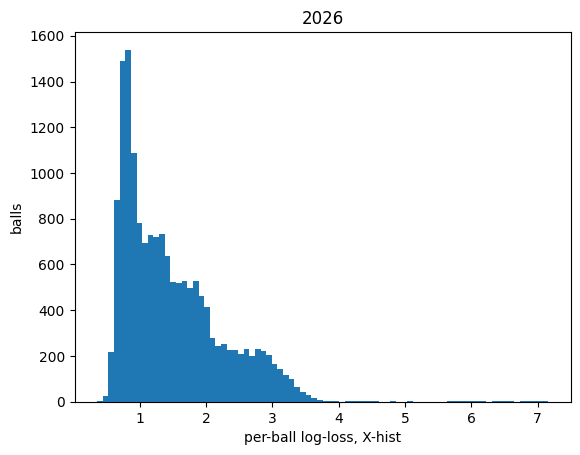

In [2]:
# ===== E1. Where X-hist's loss comes from (COPY-PASTE) =====
tab = pd.DataFrame({'outcome': np.array(NAMES)[y], 'LX': LX, 'LB0': LB0})
by = tab.groupby('outcome').agg(balls=('LX', 'size'), mean_LX=('LX', 'mean'),
                                mean_LB0=('LB0', 'mean'), sum_LX=('LX', 'sum'))
by['% balls'] = 100 * by['balls'] / len(y)
by['% of total loss'] = 100 * by['sum_LX'] / LX.sum()
by['typical p X (%)'] = 100 * np.exp(-by['mean_LX'])      # geometric-mean probability X-hist gave what happened
display(by.reindex(NAMES).drop(columns='sum_LX').round(3))

s = np.sort(LX)[::-1]
for q in (0.01, 0.05, 0.10, 0.25):
    n = int(q * len(s))
    print(f'worst {q:.0%} of balls ({n}): {100 * s[:n].sum() / s.sum():.1f}% of total loss'
          f' | they all had p(actual) below {100 * np.exp(-s[n - 1]):.2f}%')
plt.hist(LX, bins=80); plt.xlabel('per-ball log-loss, X-hist'); plt.ylabel('balls'); plt.title('2026'); plt.show()

In [3]:
# ===== E1b. Histogram as a table (COPY-PASTE) =====
edges = [0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, np.inf]
band = pd.cut(LX, edges, right=False)
h = pd.DataFrame({'band': band, 'outcome': np.array(NAMES)[y], 'LX': LX})
t = h.groupby('band', observed=False).agg(balls=('LX', 'size'), loss=('LX', 'sum'))
t['p(actual) %'] = [f'{100*np.exp(-b.right):.1f}-{100*np.exp(-b.left):.1f}' for b in t.index]
t['% balls'] = 100 * t['balls'] / len(LX)
t['% of loss'] = 100 * t['loss'] / LX.sum()
mix = pd.crosstab(h['band'], h['outcome'], dropna=False).reindex(columns=NAMES, fill_value=0)
display(t.drop(columns='loss').join(mix).round(1))

,balls,p(actual) %,% balls,% of loss,0,1,2,3,4,6,W
band,,,,,,,,,,,
"[0.0, 0.5)",20,60.7-100.0,0.1,0.0,19,1,0,0,0,0,0
"[0.5, 1.0)",5737,36.8-60.7,35.2,18.9,1223,4513,0,0,0,1,0
"[1.0, 1.5)",4071,22.3-36.8,25.0,21.0,1997,1764,0,0,262,42,6
"[1.5, 2.0)",2943,13.5-22.3,18.1,21.4,1166,60,4,0,1334,334,45
"[2.0, 2.5)",1524,8.2-13.5,9.4,14.1,89,0,108,0,622,570,135
"[2.5, 3.0)",1266,5.0-8.2,7.8,14.5,1,0,541,0,65,300,359
"[3.0, 3.5)",610,3.0-5.0,3.7,8.1,0,0,231,0,4,95,280
"[3.5, 4.0)",68,1.8-3.0,0.4,1.0,0,0,13,0,0,30,25
"[4.0, 5.0)",12,0.7-1.8,0.1,0.2,0,0,0,0,0,12,0


In [4]:
# ===== E2. Worst-predicted balls, two ways (TYPE IT) =====
ctx = pd.DataFrame({
    'match_id': match, 'venue': v['venue'].astype(str).to_numpy(), 'inn': v['innings'].to_numpy(),
    'over': [f'{b // 6}.{b % 6 + 1}' for b in v['c_team_balls'].to_numpy()],     # c_team_balls = legal balls already bowled
    'score': [f'{int(r)}/{int(w)}' for r, w in zip(v['score_before'], v['c_team_wickets'])],
    'rrr': B['rrr'].to_numpy(), 'batter': B['batter'].to_numpy(), 'bowler': B['bowler'].to_numpy(),
    'bat_pos': B['bat_pos'].to_numpy(), 'faced': B['balls_faced'].to_numpy(), 'free_hit': B['free_hit'].to_numpy(),
    'actual': np.array(NAMES)[y],
    'p X %': 100 * PX[i, y], 'p LR %': 100 * PL[i, y], 'p B1 %': 100 * PB1[i, y],
    'LX': LX, 'X-B1': LX - LB1, 'X-L': LX - LL}, index=B.index)
show = ['match_id', 'inn', 'over', 'score', 'rrr', 'batter', 'bowler', 'actual', 'p X %', 'p LR %', 'p B1 %']

# (a) Biggest surprises: top 3 per outcome by X-hist loss (threes skipped: every three is a surprise)
surprise = (ctx[ctx['actual'] != '3'].sort_values('LX', ascending=False)
            .groupby('actual', sort=False).head(3).sort_values(['actual', 'LX'], ascending=[True, False]).copy())
print('(a) Biggest surprises'); display(surprise[show].round(2))

# (b) History misled: X-hist much more wrong than B1 (situation cells only)
regret_b1 = ctx.nlargest(15, 'X-B1').copy()
print('(b) X-hist most worse than B1'); display(regret_b1[show + ['bat_pos', 'faced', 'X-B1']].round(2))

# (c) Trees misled: X-hist much more wrong than the calibrated LR on the same features
regret_l = ctx.nlargest(10, 'X-L').copy()
print('(c) X-hist most worse than B2-hist +V'); display(regret_l[show + ['free_hit', 'X-L']].round(2))

# (d) Is regret spread out or patterned? Wins vs losses, then a profile of the worst 1% against all balls
diff = LX - LB1
print(f'X-hist beats B1 on {100 * (diff < 0).mean():.1f}% of balls | total won {-diff[diff < 0].sum():.0f}, '
      f'total given back {diff[diff > 0].sum():.0f} (net {diff.sum():.0f} over {len(diff)} balls)')
worst_b1 = (ctx['X-B1'] >= ctx['X-B1'].quantile(0.99)).to_numpy()
phase = np.select([B['over0'] < 6, B['over0'] < 15], ['powerplay', 'middle'], 'death')
def profile(vals, mask):
    s = pd.Series(vals)
    return pd.DataFrame({'worst 1% (%)': 100 * s[mask].value_counts(normalize=True),
                         'all balls (%)': 100 * s.value_counts(normalize=True)}).round(1)
for name, vals in [('outcome', ctx['actual'].to_numpy()), ('phase', phase), ('batting position', ctx['bat_pos'].to_numpy())]:
    print('(d)', name); display(profile(vals, worst_b1))

(a) Biggest surprises


,match_id,inn,over,score,rrr,batter,bowler,actual,p X %,p LR %,p B1 %
290549,1529297,1,19.6,166/7,NaN,DL Chahar,Rasikh Salam,0,8.140000,17.05,21.72
278382,1527675,1,19.6,220/4,NaN,Ramandeep Singh,JJ Bumrah,0,8.790000,16.97,17.74
289360,1529292,1,19.2,223/3,NaN,H Klaasen,Vijaykumar Vyshak,0,9.190000,10.02,17.74
283626,1529268,1,19.3,174/9,NaN,C Green,Rashid Khan,1,14.950000,30.57,35.30
281313,1527688,2,19.6,181/7,6.00,MD Choudhary,VG Arora,1,15.730000,27.19,39.67
294981,1535463,2,4.5,57/4,12.20,Nithish Kumar Reddy,JC Archer,1,17.719999,25.06,28.22
293516,1529309,2,2.5,29/3,11.60,Kartik Sharma,Mohammed Siraj,2,2.300000,2.45,3.66
290691,1529298,1,1.3,29/0,NaN,Priyansh Arya,Auqib Nabi,2,2.520000,3.39,4.41
291094,1529299,2,5.6,32/4,9.67,S Arora,K Rabada,2,2.640000,2.69,3.66
279010,1527678,1,9.4,71/5,NaN,MD Choudhary,Kuldeep Yadav,4,4.020000,4.14,8.19


(b) X-hist most worse than B1


,match_id,inn,over,score,rrr,batter,bowler,actual,p X %,p LR %,p B1 %,bat_pos,faced,X-B1
293298,1529308,2,7.2,54/3,7.32,R Powell,C Bosch,6,0.82,1.62,4.71,middle,0,1.74
287764,1529285,2,10.4,111/5,4.74,JO Holder,R Shepherd,6,1.03,1.57,4.71,finisher,0,1.52
293615,1529310,1,4.5,48/1,NaN,Abhishek Sharma,JR Hazlewood,3,0.12,0.17,0.49,top,11,1.44
292601,1529305,2,15.2,143/3,10.55,AR Patel,AF Milne,3,0.08,0.15,0.28,middle,8,1.28
278944,1527677,2,18.1,147/7,8.00,XC Bartlett,M Prasidh Krishna,6,2.27,4.90,8.00,tail,2,1.26
288165,1529287,1,19.4,151/7,NaN,TA Boult,A Kamboj,6,2.13,3.03,7.27,tail,0,1.23
279978,1527682,1,12.4,126/2,NaN,R Parag,K Rabada,6,1.64,2.76,5.56,middle,0,1.22
291521,1529301,1,19.6,200/8,NaN,Vishnu Vinod,JJ Bumrah,0,9.49,14.37,31.73,tail,7,1.21
278550,1527676,1,7.3,51/5,NaN,S Dube,RA Jadeja,6,1.11,1.44,3.71,finisher,0,1.21
281797,1527691,1,0.1,0/0,NaN,SV Samson,Auqib Nabi,3,0.15,0.18,0.49,top,0,1.19


(c) X-hist most worse than B2-hist +V


,match_id,inn,over,score,rrr,batter,bowler,actual,p X %,p LR %,p B1 %,free_hit,X-L
289241,1529292,1,0.2,0/0,NaN,Abhishek Sharma,Arshdeep Singh,6,2.62,6.79,3.72,False,0.95
290681,1529298,1,0.1,0/0,NaN,Priyansh Arya,MA Starc,6,1.58,3.89,3.72,False,0.90
290077,1529295,2,0.2,1/0,11.55,V Suryavanshi,Mohammed Siraj,6,2.45,5.63,4.16,False,0.83
278944,1527677,2,18.1,147/7,8.00,XC Bartlett,M Prasidh Krishna,6,2.27,4.90,8.00,False,0.77
287462,1529284,2,0.2,0/0,12.30,Abhishek Sharma,TA Boult,6,5.10,10.82,4.16,False,0.75
292646,1529306,1,2.5,31/1,NaN,Urvil Patel,PJ Cummins,6,2.65,5.57,3.72,False,0.74
290549,1529297,1,19.6,166/7,NaN,DL Chahar,Rasikh Salam,0,8.14,17.05,21.72,False,0.74
283626,1529268,1,19.3,174/9,NaN,C Green,Rashid Khan,1,14.95,30.57,35.30,False,0.72
292601,1529305,2,15.2,143/3,10.55,AR Patel,AF Milne,3,0.08,0.15,0.28,False,0.68
290269,1529296,1,14.4,147/6,NaN,Himmat Singh,J Overton,6,1.63,3.22,2.31,False,0.68


... (2 outputs left out)

(d) phase


,worst 1% (%),all balls (%)
death,33.1,22.0
middle,36.8,46.6
powerplay,30.1,31.4


(d) batting position


,worst 1% (%),all balls (%)
finisher,22.1,18.3
middle,19.6,27.1
tail,7.4,3.3
top,50.9,51.3


In [5]:
# ===== E2b. Early-innings sixes: predicted vs actual, 2025 and 2026 (COPY-PASTE) =====
def six_check(Bd):
    y_, o, f = Bd['y'].to_numpy().astype(int), Bd['over0'].to_numpy(), Bd['balls_faced'].to_numpy()
    top = Bd['bat_pos'].astype(str).to_numpy() == 'top'
    G = {"batter's first ball": f == 0, 'over 0': o == 0, 'over 0, top order': (o == 0) & top,
         'overs 1-5': (o >= 1) & (o < 6), 'all balls': np.ones(len(y_), bool)}
    rows = []
    for g, m in G.items():
        a = (y_[m] == 5).mean()
        rows.append({'group': g, 'balls': int(m.sum()), 'actual %': 100 * a, '±2SE': 200 * np.sqrt(a * (1 - a) / m.sum()),
                     **{f'{n} %': 100 * Bd.loc[m, f'p{t}_5'].mean() for n, t in [('X', 'x'), ('LR', 'l'), ('B1', 'b1')]}})
    return pd.DataFrame(rows).set_index('group').round(2)
for yr in (2025, 2026):
    print(yr); display(six_check(pd.read_parquet(DATA + f'bundle_{yr}.parquet')))

2025


,balls,actual %,±2SE,X %,LR %,B1 %
group,,,,,,
batter's first ball,1061,2.64,0.98,2.23,2.62,4.83
over 0,828,2.78,1.14,3.23,3.62,3.72
"over 0, top order",827,2.78,1.14,3.23,3.62,3.72
overs 1-5,4140,8.07,0.85,7.83,8.15,3.64
all balls,15809,7.93,0.43,8.98,9.08,5.05


2026


,balls,actual %,±2SE,X %,LR %,B1 %
group,,,,,,
batter's first ball,1093,2.74,0.99,2.34,2.92,4.88
over 0,852,5.40,1.55,3.85,4.11,3.94
"over 0, top order",847,5.43,1.56,3.86,4.12,3.94
overs 1-5,4260,9.15,0.88,8.15,7.90,3.83
all balls,16282,8.50,0.44,8.65,7.93,5.21


In [6]:
# ===== E3a. SHAP contributions from the saved 2026 model (COPY-PASTE) =====
def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True); E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

bst = xgb.Booster(); bst.load_model(DATA + 'xgb_X-hist_2026.json')
bst.set_param({'device': 'cuda'})                              # falls back to CPU with a warning if no GPU (slower, same values)
dm = xgb.DMatrix(v[FEAT_HIST], enable_categorical=True)
margin = bst.predict(dm, output_margin=True)                   # (n, 7) raw class scores
phi = bst.predict(dm, pred_contribs=True)                      # (n, 7, 88): per class, per feature; last column = bias
PXm = softmax(margin)

print('1. feature names match:', bst.feature_names == FEAT_HIST)                       # expect True
print('2. same model as the bundle:', np.abs(PXm - PX).max())                           # expect below 1e-5
print('3. contributions add up to the scores:', np.abs(phi.sum(axis=2) - margin).max())  # expect below 1e-3
print('4. shape:', phi.shape, '| bias same for every ball:', np.allclose(phi[:, :, -1], phi[0, :, -1]))   # (16282, 7, 88) | True

1. feature names match: True
2. same model as the bundle: 1.1920929e-07
3. contributions add up to the scores: 5.2452087e-06
4. shape: (16282, 7, 88) | bias same for every ball: True


In [7]:
# ===== E3b. Push toward the actual outcome (TYPE IT) =====
F = phi[:, :, :-1]                                              # drop the bias column -> (n, 7, 87)
push = F[i, y, :] - np.einsum('nk,nkf->nf', PXm, F)             # (n, 87): actual class minus p-weighted average
PUSH = pd.DataFrame(push, columns=FEAT_HIST, index=B.index)
GPUSH = PUSH.T.groupby(GROUP_OF).sum().T                        # (n, 5): one column per feature group

P0 = softmax(phi[:, :, -1])                                     # bias-only prediction
kl = (PXm * np.log(PXm / P0)).sum(axis=1)
exact = np.log(PXm[i, y]) - np.log(P0[i, y]) - kl
print('5. push adds up exactly:', np.abs(push.sum(axis=1) - exact).max())   # expect below 1e-3

5. push adds up exactly: 2.6524067e-06


In [8]:
# ===== E3c. Push summaries and reasons for the listed balls (COPY-PASTE) =====
summ = pd.DataFrame({'mean |push| all': GPUSH.abs().mean(), 'mean push all': GPUSH.mean(),
                     'mean push death': GPUSH[death].mean(), 'mean push worst 1% vs B1': GPUSH[worst_b1].mean()})
print('By group'); display(summ.sort_values('mean |push| all', ascending=False).round(4))

fi = pd.DataFrame({'group': [GROUP_OF[f] for f in FEAT_HIST], 'mean |push|': PUSH.abs().mean().values,
                   'mean push': PUSH.mean().values}, index=FEAT_HIST)
print('Top 15 features by mean |push|'); display(fi.sort_values('mean |push|', ascending=False).head(15).round(4))

def fmt(x): return f'{x:.3g}' if isinstance(x, (float, np.floating)) else str(x)
def reasons(ix, n=3):
    r = PUSH.loc[ix].nsmallest(n)                               # most negative push = pushed away hardest
    return '; '.join(f'{f}={fmt(v.at[ix, f])} ({p:+.2f})' for f, p in r.items())
for tbl in (surprise, regret_b1, regret_l):
    tbl['pushed away'] = [reasons(ix) for ix in tbl.index]
pd.set_option('display.max_colwidth', 200)
print('(b) with reasons'); display(regret_b1[['batter', 'bowler', 'over', 'actual', 'p X %', 'p B1 %', 'pushed away']].round(2))
print('(c) with reasons'); display(regret_l[['batter', 'over', 'actual', 'free_hit', 'p X %', 'p LR %', 'pushed away']].round(2))

By group


,mean |push| all,mean push all,mean push death,mean push worst 1% vs B1
situation,0.2366,-0.0027,-0.0194,-0.5833
8_batter,0.1043,-0.0014,-0.0093,-0.1113
9_bowler,0.0484,-0.0006,-0.0028,-0.0537
11_venue_season,0.0478,-0.0009,-0.0023,-0.0688
10_base,0.0128,-0.0001,0.0006,-0.0131


Top 15 features by mean |push|


,group,mean |push|,mean push
balls_per_wicket_remaining,situation,0.0829,-0.0008
c_team_balls,situation,0.0819,0.0011
bat_six_pct_3s,8_batter,0.0479,0.0002
bat_sr_phase,8_batter,0.0389,-0.0007
season_rpo,11_venue_season,0.0331,-0.0003
bowl_dot_pct_3s,9_bowler,0.0311,0.0000
balls_remaining,situation,0.0289,0.0001
bat_bdry_pct_3s,8_batter,0.0288,-0.0004
c_batter_balls,situation,0.0254,-0.0010
c_batter_runs,situation,0.0253,-0.0004


(b) with reasons


,batter,bowler,over,actual,p X %,p B1 %,pushed away
293298,R Powell,C Bosch,7.2,6,0.82,4.71,c_batter_balls=0 (-0.43); partnership_runs=0 (-0.33); balls_per_wicket_remaining=11 (-0.21)
287764,JO Holder,R Shepherd,10.4,6,1.03,4.71,c_batter_balls=0 (-0.42); partnership_runs=0 (-0.34); balls_per_wicket_remaining=11.4 (-0.18)
293615,Abhishek Sharma,JR Hazlewood,4.5,3,0.12,0.49,bat_six_pct_3s=0.143 (-0.29); venue_bdry_pct_3s=0.228 (-0.16); bat_out_pct_3s=0.0536 (-0.14)
292601,AR Patel,AF Milne,15.2,3,0.08,0.28,bat_six_pct_3s=0.0651 (-0.30); bat_out_pct_3s=0.0574 (-0.15); venue_bdry_pct_3s=0.239 (-0.14)
278944,XC Bartlett,M Prasidh Krishna,18.1,6,2.27,8.00,bat_sr_phase=114 (-0.26); partnership_runs=3 (-0.13); c_batter_balls=2 (-0.13)
288165,TA Boult,A Kamboj,19.4,6,2.13,7.27,bat_sr_phase=108 (-0.32); c_batter_balls=0 (-0.31); partnership_runs=0 (-0.24)
279978,R Parag,K Rabada,12.4,6,1.64,5.56,c_batter_balls=0 (-0.39); partnership_runs=0 (-0.33); c_batter_runs=0 (-0.22)
291521,Vishnu Vinod,JJ Bumrah,19.6,0,9.49,31.73,balls_per_wicket_remaining=0.5 (-0.79); c_team_balls=119 (-0.38); c_team_runs=200 (-0.08)
278550,S Dube,RA Jadeja,7.3,6,1.11,3.71,c_batter_balls=0 (-0.44); partnership_runs=0 (-0.32); balls_per_wicket_remaining=15.2 (-0.27)
281797,SV Samson,Auqib Nabi,0.1,3,0.15,0.49,bat_six_pct_3s=0.0687 (-0.24); non_striker_sr=nan (-0.12); venue_bdry_pct_3s=0.181 (-0.11)


(c) with reasons


,batter,over,actual,free_hit,p X %,p LR %,pushed away
289241,Abhishek Sharma,0.2,6,False,2.62,6.79,c_batter_balls=1 (-0.30); partnership_runs=0 (-0.28); balls_per_wicket_remaining=11.9 (-0.24)
290681,Priyansh Arya,0.1,6,False,1.58,3.89,c_batter_balls=0 (-0.43); partnership_runs=0 (-0.32); balls_per_wicket_remaining=12 (-0.27)
290077,V Suryavanshi,0.2,6,False,2.45,5.63,c_batter_balls=0 (-0.41); partnership_runs=1 (-0.27); balls_per_wicket_remaining=11.9 (-0.25)
278944,XC Bartlett,18.1,6,False,2.27,4.90,bat_sr_phase=114 (-0.26); partnership_runs=3 (-0.13); c_batter_balls=2 (-0.13)
287462,Abhishek Sharma,0.2,6,False,5.10,10.82,c_batter_balls=1 (-0.26); partnership_runs=0 (-0.22); balls_per_wicket_remaining=11.9 (-0.20)
292646,Urvil Patel,2.5,6,False,2.65,5.57,c_batter_balls=1 (-0.30); partnership_runs=0 (-0.28); balls_per_wicket_remaining=11.6 (-0.24)
290549,DL Chahar,19.6,0,False,8.14,17.05,balls_per_wicket_remaining=0.333 (-0.89); c_team_balls=119 (-0.45); c_team_runs=166 (-0.09)
283626,C Green,19.3,1,False,14.95,30.57,c_team_balls=116 (-0.30); balls_remaining=4 (-0.19); non_striker_pos=11 (-0.18)
292601,AR Patel,15.2,3,False,0.08,0.15,bat_six_pct_3s=0.0651 (-0.30); bat_out_pct_3s=0.0574 (-0.15); venue_bdry_pct_3s=0.239 (-0.14)
290269,Himmat Singh,14.4,6,False,1.63,3.22,partnership_runs=0 (-0.30); c_batter_balls=1 (-0.24); bat_sr_phase=114 (-0.23)


In [9]:
# ===== E3d. Intervals for mean push (COPY-PASTE) =====
def boot_mean(x, mask, n_boot=2000, seed=0):
    codes, _ = pd.factorize(match[mask])
    s, c = np.bincount(codes, weights=x[mask]), np.bincount(codes)
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    b = s[idx].sum(axis=1) / c[idx].sum(axis=1)
    return x[mask].mean(), *np.percentile(b, [2.5, 97.5])

top10 = fi.sort_values('mean |push|', ascending=False).index[:10]
cols = list(GPUSH.items()) + [(f, PUSH[f]) for f in top10]
rows = []
for name, col in cols:
    x = col.to_numpy()
    for sl, m in [('all', np.ones(len(y), bool)), ('death', death)]:
        mean, lo, hi = boot_mean(x, m)
        rows.append({'name': name, 'slice': sl, 'mean |push|': np.abs(x[m]).mean(), 'mean push': mean, 'low': lo, 'high': hi,
                     'reading': 'used about right' if lo <= 0 <= hi else ('under-used' if lo > 0 else 'over-trusted')})
display(pd.DataFrame(rows).set_index(['name', 'slice']).round(4))

mean |push|  mean push     low    high  \
name                       slice                                           
10_base                    all         0.0128    -0.0001 -0.0004  0.0002   
                           death       0.0188     0.0006 -0.0002  0.0014   
11_venue_season            all         0.0478    -0.0009 -0.0021  0.0003   
                           death       0.0450    -0.0023 -0.0044 -0.0002   
8_batter                   all         0.1043    -0.0014 -0.0040  0.0011   
                           death       0.1231    -0.0093 -0.0158 -0.0028   
9_bowler                   all         0.0484    -0.0006 -0.0016  0.0004   
                           death       0.0444    -0.0028 -0.0046 -0.0010   
situation                  all         0.2366    -0.0027 -0.0083  0.0030   
                           death       0.2526    -0.0194 -0.0314 -0.0076   
balls_per_wicket_remaining all         0.0829    -0.0008 -0.0027  0.0013   
                           death       0.1094    -0.0085 -0.0136 -0.0029   
c_team_balls               all         0.0819     0.0011 -0.0007  0.0028   
                           death       0.0711    -0.0031 -0.0064  0.0003   
bat_six_pct_3s             all         0.0479     0.0002 -0.0011  0.0014   
                           death       0.0476    -0.0021 -0.0049  0.0006   
bat_sr_phase               all         0.0389    -0.0007 -0.0018  0.0003   
                           death       0.0570    -0.0046 -0.0077 -0.0017   
season_rpo                 all         0.0331    -0.0003 -0.0010  0.0005   
                           death       0.0289    -0.0004 -0.0015  0.0006   
bowl_dot_pct_3s            all         0.0311     0.0000 -0.0007  0.0006   
                           death       0.0200    -0.0009 -0.0019  0.0000   
balls_remaining            all         0.0289     0.0001 -0.0005  0.0007   
                           death       0.0266    -0.0014 -0.0027 -0.0001   
bat_bdry_pct_3s            all         0.0288    -0.0004 -0.0011  0.0002   
                           death       0.0249    -0.0008 -0.0019  0.0003   
c_batter_balls             all         0.0254    -0.0010 -0.0016 -0.0003   
                           death       0.0178     0.0001 -0.0009  0.0011   
c_batter_runs              all         0.0253    -0.0004 -0.0009  0.0002   
                           death       0.0302    -0.0009 -0.0023  0.0006   

                                           reading  
name                       slice                    
10_base                    all    used about right  
                           death  used about right  
11_venue_season            all    used about right  
                           death      over-trusted  
8_batter                   all    used about right  
                           death      over-trusted  
9_bowler                   all    used about right  
                           death      over-trusted  
situation                  all    used about right  
                           death      over-trusted  
balls_per_wicket_remaining all    used about right  
                           death      over-trusted  
c_team_balls               all    used about right  
                           death  used about right  
bat_six_pct_3s             all    used about right  
                           death  used about right  
bat_sr_phase               all    used about right  
                           death      over-trusted  
season_rpo                 all    used about right  
                           death  used about right  
bowl_dot_pct_3s            all    used about right  
                           death  used about right  
balls_remaining            all    used about right  
                           death      over-trusted  
bat_bdry_pct_3s            all    used about right  
                           death  used about right  
c_batter_balls             all        over-trusted  
                           death  used about right  
c_batter_ru

In [10]:
# ===== E3e. Dots and sixes by balls per wicket remaining (COPY-PASTE) =====
bpw = v['balls_per_wicket_remaining'].to_numpy()
band = pd.cut(bpw, [0, 1, 2, 4, 8, 12, 20, np.inf], right=False)
t = pd.DataFrame({'band': band, 'dot': y == 0, 'six': y == 5, 'p dot': PX[:, 0], 'p six': PX[:, 5]})
g = t.groupby('band', observed=True).agg(balls=('dot', 'size'), dot_act=('dot', 'mean'), dot_X=('p dot', 'mean'),
                                         six_act=('six', 'mean'), six_X=('p six', 'mean'))
g[['dot_act', 'dot_X', 'six_act', 'six_X']] *= 100
g['±2SE dot'] = 200 * np.sqrt(g['dot_act'] / 100 * (1 - g['dot_act'] / 100) / g['balls'])
display(g.round(2))

,balls,dot_act,dot_X,six_act,six_X,±2SE dot
band,,,,,,
"[0.0, 1.0)",287,13.94,12.660000,18.12,17.27,4.09
"[1.0, 2.0)",550,18.36,15.820000,11.64,14.77,3.30
"[2.0, 4.0)",1568,19.90,17.830000,10.71,11.54,2.02
"[4.0, 8.0)",4787,21.77,20.889999,8.90,9.39,1.19
"[8.0, 12.0)",7250,30.52,30.090000,8.21,7.66,1.08
"[12.0, 20.0)",1741,41.93,40.849998,4.42,5.09,2.37
"[20.0, inf)",99,57.58,45.810001,2.02,3.90,9.93


In [11]:
# ===== E4a. Free-hit wickets (COPY-PASTE) =====
fh, W = B['free_hit'].to_numpy(), 6
print('mean p(W) %, free hits vs all balls:', round(100 * PX[fh, W].mean(), 2), round(100 * PX[:, W].mean(), 2))   # 5.94 vs ~5
dW = pd.Series(F[fh, W, :].mean(axis=0) - F[:, W, :].mean(axis=0), index=FEAT_HIST)
print('wicket-score contributions, free hits minus all balls'); display(pd.concat([dW.nsmallest(5), dW.nlargest(5)]).round(3))

if 'is_free_hit' in FEAT_HIST:
    print('is_free_hit contribution to the wicket score on free hits:', F[fh, W, FEAT_HIST.index('is_free_hit')].mean().round(3))
    dumps = bst.get_dump()                                      # one text dump per tree; tree t belongs to class t % 7
    n_split = [t.count('[is_free_hit') for t in dumps]
    print('trees:', len(dumps), '| splits on is_free_hit per class 0,1,2,3,4,6,W:',
          np.bincount(np.arange(len(dumps)) % 7, weights=n_split, minlength=7).astype(int).tolist())
    n_fh = int((d.loc[d['split'].isin(['train', 'val']), 'is_free_hit'].astype(float) > 0).sum())
    pW = PX[fh, W].mean()
    print(f'free hits in 2008-2025: {n_fh} | wicket-class weight per tree ≈ 0.8 × {n_fh} × 2p(1-p) = '
          f'{0.8 * n_fh * 2 * pW * (1 - pW):.0f} (min_child_weight = 100)')
else:
    print('is_free_hit is not an X-hist feature')

mean p(W) %, free hits vs all balls: 5.94 5.56
wicket-score contributions, free hits minus all balls


,0
prev_ball_outcome,-0.036
bowler_econ_match,-0.015
runs_this_over,-0.008
season_rpo,-0.002
bat_out_pct_matchup,-0.002
c_team_balls,0.070
required_run_rate,0.017
balls_remaining,0.016
bat_out_pct_phase,0.015
balls_per_wicket_remaining,0.013


is_free_hit contribution to the wicket score on free hits: 0.0
trees: 2107 | splits on is_free_hit per class 0,1,2,3,4,6,W: [7, 2, 0, 0, 41, 41, 0]
free hits in 2008-2025: 1061 | wicket-class weight per tree ≈ 0.8 × 1061 × 2p(1-p) = 95 (min_child_weight = 100)


In [13]:
# ===== E4b. Lost-chase sixes (COPY-PASTE) =====
rrr, inn2, S6 = B['rrr'].to_numpy(), B['innings2'].to_numpy(), 5
lc = inn2 & (rrr > 18)
ref = inn2 & death & ~lc                                        # other death-over balls in chases
for name, m in [('RRR > 18', lc), ('other death chase balls', ref)]:
    print(f'{name}: {m.sum()} balls | p(6) predicted {100 * PX[m, S6].mean():.2f}% vs actual {100 * (y[m] == S6).mean():.2f}%'
          f' | tail-enders {100 * (ctx["bat_pos"].to_numpy()[m] == "tail").mean():.0f}%')
d6 = pd.Series(F[lc, S6, :].mean(axis=0) - F[ref, S6, :].mean(axis=0), index=FEAT_HIST)
print('six-score contributions, RRR > 18 minus other death chase balls'); display(pd.concat([d6.nlargest(8), d6.nsmallest(4)]).round(3))

RRR > 18: 466 balls | p(6) predicted 12.00% vs actual 8.58% | tail-enders 37%
other death chase balls: 1105 balls | p(6) predicted 10.52% vs actual 10.86% | tail-enders 6%
six-score contributions, RRR > 18 minus other death chase balls


,0
required_run_rate,0.225
pressure_diff,0.106
runs_target,0.035
target_vs_par,0.024
recent_pressure_diff,0.014
bat_out_pct_3s,0.011
c_team_balls,0.011
bowl_dot_pct_3s,0.009
bat_sr_phase,-0.171
balls_per_wicket_remaining,-0.046


In [14]:
# ===== E5. Save (COPY-PASTE) =====
lists = pd.concat({'surprise': surprise, 'history misled': regret_b1, 'trees misled': regret_l}, names=['list', 'row_id'])
lists.to_csv(DATA + 'worst_balls_2026.csv')
summ.to_csv(DATA + 'push_by_group_2026.csv'); fi.to_csv(DATA + 'push_by_feature_2026.csv')

M = (pd.DataFrame({'match_id': match, 'LX': LX, 'X-B1': LX - LB1})
       .groupby('match_id').agg(balls=('LX', 'size'), LX=('LX', 'mean'), gain_vs_B1=('X-B1', 'mean')))
print('Most predictable matches'); display(M.sort_values('LX').head(3).round(4))
print('Least predictable matches'); display(M.sort_values('LX').tail(3).round(4))
M.to_csv(DATA + 'matches_2026.csv')

ctx.join(GPUSH.add_prefix('push ')).to_parquet(DATA + 'balls_2026_explained.parquet')
print('saved', len(lists), 'listed balls,', len(M), 'matches,', len(ctx), 'balls')   # expect 18+15+10 = 43 | 71 | 16282

Most predictable matches


,balls,LX,gain_vs_B1
match_id,,,
1529282,138,1.3677,-0.0863
1529276,234,1.3728,-0.0411
1529294,206,1.3730,-0.0709


Least predictable matches


,balls,LX,gain_vs_B1
match_id,,,
1529295,219,1.5968,-0.0171
1529279,231,1.5972,-0.0589
1529309,202,1.6008,-0.0314


saved 43 listed balls, 71 matches, 16282 balls


In [20]:
# ===== E5b. Candidate replay matches (COPY-PASTE) =====
S = (pd.DataFrame({'match_id': match, 'free_hit': B['free_hit'].to_numpy(), 'lost_chase': lc})
       .groupby('match_id').agg(balls=('free_hit', 'size'), free_hits=('free_hit', 'sum'), lost_chase_balls=('lost_chase', 'sum')))
S['listed balls'] = lists['match_id'].value_counts().reindex(S.index).fillna(0).astype(int)
S = S.join(M[['LX', 'gain_vs_B1']])
display(S.query('balls >= 220').sort_values(['listed balls', 'free_hits'], ascending=False).head(8).round(4))

,balls,free_hits,lost_chase_balls,listed balls,LX,gain_vs_B1
match_id,,,,,,
1529298,234,3,0,2,1.5227,0.0019
1529292,240,2,36,2,1.4957,-0.0531
1527677,235,1,0,2,1.5024,0.0113
1527682,240,1,2,2,1.5683,0.0022
1529268,238,1,0,2,1.5306,-0.0228
1529297,240,1,0,2,1.4719,-0.0217
1529308,233,1,0,2,1.4337,-0.0382
1529302,220,0,0,2,1.4829,-0.0450


In [21]:
import os
print(pd.DataFrame(rows).columns.tolist()[:4])     # expect ['name', 'slice', 'mean |push|', 'mean push']
pd.DataFrame(rows).to_csv(DATA + 'push_intervals_2026.csv', index=False)   # E3d table
g.to_csv(DATA + 'bpw_bands_2026.csv')                                       # E3e table
print(sorted(f for f in os.listdir(DATA) if f.endswith('_2026.csv')))

['name', 'slice', 'mean |push|', 'mean push']
['bpw_bands_2026.csv', 'ece_2026.csv', 'failure_calibration_2026.csv', 'matches_2026.csv', 'paired_2026.csv', 'players_bat_2026.csv', 'players_bowl_2026.csv', 'preregistered_2026.csv', 'push_by_feature_2026.csv', 'push_by_group_2026.csv', 'push_intervals_2026.csv', 'results_2026.csv', 'slices_2026.csv', 'worst_balls_2026.csv']
